In [1]:
# Importing the libraries for data handling, plotting and text processing; hide warnings for clean output
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Importing nltk and also downloading the resources needed for tokenizing, stopwords and lemmatizing
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to C:\Users\DESTINY
[nltk_data]     OJI\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\DESTINY
[nltk_data]     OJI\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\DESTINY
[nltk_data]     OJI\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\DESTINY
[nltk_data]     OJI\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\DESTINY
[nltk_data]     OJI\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
path = "3) Sentiment dataset.csv"
df = pd.read_csv(path)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


In [5]:
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [6]:
df.shape

(732, 15)

In [7]:
# Removing stray spaces from the labels and the text
df['Sentiment'] = df['Sentiment'].str.strip()
df['Text'] = df['Text'].str.strip()

In [8]:
# Counting the unique labels and how often each one appears
print("Unique labels:", df['Sentiment'].nunique())
print()
print(df['Sentiment'].value_counts().head(30))

Unique labels: 191

Sentiment
Positive         45
Joy              44
Excitement       37
Contentment      19
Neutral          18
Gratitude        18
Curiosity        16
Serenity         15
Happy            14
Nostalgia        11
Despair          11
Grief             9
Awe               9
Sad               9
Hopeful           9
Loneliness        9
Embarrassed       8
Acceptance        8
Confusion         8
Euphoria          7
Elation           7
Enthusiasm        7
Pride             7
Determination     7
Regret            6
Frustration       6
Ambivalence       6
Melancholy        6
Numbness          6
Playful           6
Name: count, dtype: int64


In [9]:
# Print all 191 labels once so we can see exactly what needs grouping
print(sorted(df['Sentiment'].str.strip().unique()))

['Acceptance', 'Accomplishment', 'Admiration', 'Adoration', 'Adrenaline', 'Adventure', 'Affection', 'Amazement', 'Ambivalence', 'Amusement', 'Anger', 'Anticipation', 'Anxiety', 'Appreciation', 'Apprehensive', 'Arousal', 'ArtisticBurst', 'Awe', 'Bad', 'Betrayal', 'Bitter', 'Bitterness', 'Bittersweet', 'Blessed', 'Boredom', 'Breakthrough', 'Calmness', 'Captivation', 'Celebration', 'Celestial Wonder', 'Challenge', 'Charm', 'Colorful', 'Compassion', 'Compassionate', 'Confidence', 'Confident', 'Confusion', 'Connection', 'Contemplation', 'Contentment', 'Coziness', 'Creative Inspiration', 'Creativity', 'Culinary Adventure', 'CulinaryOdyssey', 'Curiosity', 'Darkness', 'Dazzle', 'Desolation', 'Despair', 'Desperation', 'Determination', 'Devastated', 'Disappointed', 'Disappointment', 'Disgust', 'Dismissive', 'DreamChaser', 'Ecstasy', 'Elation', 'Elegance', 'Embarrassed', 'Emotion', 'EmotionalStorm', 'Empathetic', 'Empowerment', 'Enchantment', 'Energy', 'Engagement', 'Enjoyment', 'Enthusiasm', 'En

In [10]:
# Grouping all 191 emotion labels into three sentiment classes
# Clearly positive or negative feelings go to their class, and ambiguous or reflective ones go to Neutral
positive = {
    # joy and excitement
    'positive', 'positivity', 'joy', 'happy', 'happiness', 'excitement', 'enthusiasm', 'euphoria',
    'elation', 'ecstasy', 'overjoyed', 'amusement', 'enjoyment', 'playful', 'playfuljoy',
    'festivejoy', 'joyfulreunion', 'joy in baking', 'zest', 'thrill', 'thrilling journey',
    'adrenaline', 'celebration', 'whimsy', 'mischievous',
    # calm and contentment
    'contentment', 'serenity', 'calmness', 'tranquility', 'harmony', 'coziness', 'relief', 'solace',
    'rejuvenation', 'satisfaction', 'fulfillment',
    # gratitude and warmth
    'gratitude', 'grateful', 'appreciation', 'blessed', 'touched', 'heartwarming',
    # love and kindness
    'love', 'adoration', 'affection', 'admiration', 'romance', 'tenderness', 'friendship',
    'connection', 'kind', 'kindness', 'compassion', 'compassionate', 'empathetic',
    # hope, drive and achievement
    'hope', 'hopeful', 'optimism', 'determination', 'renewed effort', 'resilience', 'motivation',
    'empowerment', 'confidence', 'confident', 'pride', 'proud', 'accomplishment', 'success',
    'triumph', 'breakthrough', 'inspiration', 'inspired', 'creative inspiration', 'dreamchaser',
    # awe and beauty
    'awe', 'amazement', 'wonder', 'wonderment', 'marvel', 'reverence', 'enchantment', 'captivation',
    'mesmerizing', 'hypnotic', 'dazzle', 'radiance', 'charm', 'elegance', 'grandeur', 'iconic',
    'vibrancy', 'colorful', 'spark', 'energy', 'engagement', 'immersion', 'arousal',
    # creativity, adventure and freedom
    'creativity', 'imagination', 'artisticburst', 'runway creativity', 'melodic',
    'adventure', 'culinary adventure', 'culinaryodyssey', 'exploration', 'freedom', 'free-spirited',
    "ocean's freedom", "nature's beauty", 'celestial wonder', 'winter magic',
}



In [11]:
negative = {
    # sadness and loss
    'negative', 'bad', 'sad', 'sadness', 'sorrow', 'grief', 'heartache', 'heartbreak', 'loss',
    'lostlove', 'melancholy', 'despair', 'desperation', 'desolation', 'devastated', 'suffering',
    'loneliness', 'isolation', 'numbness', 'helplessness', 'darkness', 'ruins',
    # anger and resentment
    'anger', 'hate', 'resentment', 'bitter', 'bitterness', 'disgust', 'dismissive',
    'jealous', 'jealousy', 'envious', 'envy', 'betrayal',
    # fear and stress
    'fear', 'fearful', 'anxiety', 'apprehensive', 'intimidation', 'overwhelmed', 'pressure',
    # frustration and disappointment
    'frustrated', 'frustration', 'disappointed', 'disappointment', 'regret', 'shame', 'embarrassed',
    'boredom', 'exhaustion', 'obstacle', 'miscalculation', 'emotionalstorm',
}


In [12]:
neutral = {
    # explicitly neutral or unspecified
    'neutral', 'emotion',
    # mixed or ambiguous feelings
    'acceptance', 'ambivalence', 'anticipation', 'bittersweet', 'challenge', 'confusion',
    # reflective states
    'contemplation', 'reflection', 'mindfulness', 'pensive', 'curiosity', 'intrigue',
    'surprise', 'suspense', 'nostalgia', 'yearning', 'whispers of the past', 'envisioning history',
    # detached or observational
    'indifference', 'solitude', 'sympathy', 'journey', 'innerjourney',
}


In [13]:
def group_label(s):
    s = str(s).strip().lower().replace("\u2019", "'")
    if s in positive: return 'Positive'
    if s in negative: return 'Negative'
    if s in neutral:  return 'Neutral'
    return 'Unmapped'

df['Label'] = df['Sentiment'].apply(group_label)

##### Safety Check

In [14]:
#confirming every row received a class
unmapped = df.loc[df['Label'] == 'Unmapped', 'Sentiment'].str.strip().value_counts()
print("Unmapped rows:", unmapped.sum())
print(unmapped)

Unmapped rows: 0
Series([], Name: count, dtype: int64)


In [15]:
# Checking for repeated texts, because the same text in both train and test would inflate the scores
dup_count = df.duplicated(subset='Text').sum()
print("Duplicate texts:", dup_count)

df = df.drop_duplicates(subset='Text').reset_index(drop=True)

Duplicate texts: 26


In [16]:
# Class balance after gouping the 191 emotions into 3
print(df['Label'].value_counts())
print()
print(df['Label'].value_counts(normalize=True).round(3))

Label
Positive    421
Negative    181
Neutral     104
Name: count, dtype: int64

Label
Positive    0.596
Negative    0.256
Neutral     0.147
Name: proportion, dtype: float64


In [17]:
# Spot-checking the grouping by reading real texts from each class
for c in ['Positive', 'Negative', 'Neutral']:
    print(f"--- {c} ---")
    for _, row in df[df['Label'] == c].sample(3, random_state=1).iterrows():
        print(f"[{row['Sentiment'].strip()}] {row['Text'][:100]}")
    print()

--- Positive ---
[Excitement] Daydreaming about the upcoming prom. The dress, the dance – it's a fairytale in the making!
[Playful] Playfully juggling responsibilities, a circus performer balancing the acts of work and joy, tossing 
[Positive] Sunday brunch with friends.

--- Negative ---
[Grief] In the labyrinth of grief, the walls echo with the footsteps of lost joy.
[Envious] Envious eyes locked on the treasure chest of opportunities, a heartache fueled by the desire for key
[Desperation] Desperation whispers, the silent plea for a glimmer of hope in the abyss.

--- Neutral ---
[Neutral] Exploring a new part-time job opportunity for gaining work experience. Career development in progres
[Ambivalence] Ambivalence clouding decisions, caught in the crossroads of conflicting emotions.
[Surprise] Decided to study for exams but ended up making memes about studying instead. Procrastination level: 



### Exploring the Classes and text length

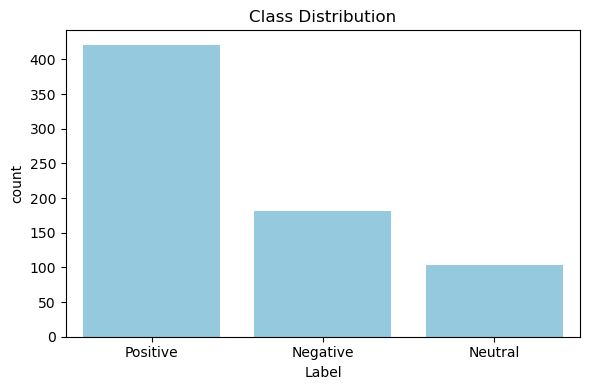

In [18]:
# Plotting the class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Label', order=df['Label'].value_counts().index, color='skyblue')
plt.title('Class Distribution')
plt.tight_layout()
plt.show()

In [19]:
# Measuring the length in words
df['word_count'] = df['Text'].apply(lambda x: len(str(x).split()))
df['word_count'].describe()

count    706.000000
mean      13.048159
std        4.838141
min        4.000000
25%        9.000000
50%       13.000000
75%       17.000000
max       25.000000
Name: word_count, dtype: float64

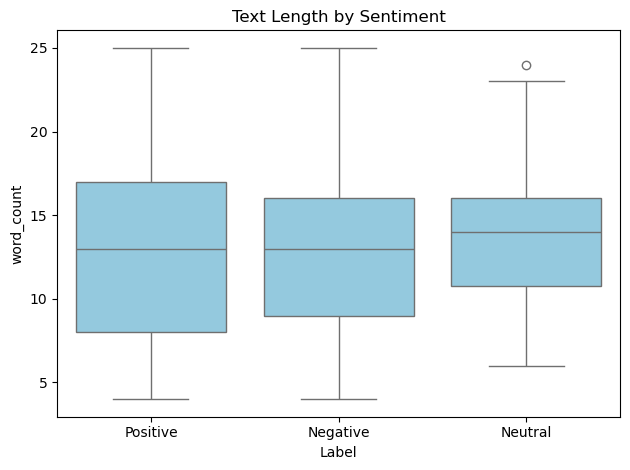

In [20]:
# Comparing the length across classes
sns.boxplot(data=df, x='Label', y='word_count', color='skyblue')
plt.title('Text Length by Sentiment')
plt.tight_layout()
plt.show()

### Text preprocessing

In [21]:
# Loading the nltk tools for stopwords, tokenizing, lemmatizing and stemming
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer, PorterStemmer

lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

In [22]:
# Building the stopword list but keep negations, since "not good" and "good" have opposite sentiment
negations = {'no', 'not', 'nor', 'never'}
stop_words = set(stopwords.words('english')) - negations
print(len(stop_words), "stopwords will be removed")

195 stopwords will be removed


In [23]:
# Cleaning one text: lowercase, strip URLs, mentions and punctuation, and turn "don't" into "do not" so negations survive
def clean_text(text):
    text = str(text).lower()
    text = text.replace("’", "'")
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#", " ", text)
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [24]:
# Tokenizing and removing stopwords and very short tokens, then lemmatize as noun and then verb ("movies" -> "movie", "feeling" -> "feel")
def preprocess(text):
    tokens = word_tokenize(clean_text(text))
    tokens = [t for t in tokens if t not in stop_words and (len(t) > 2 or t in negations)]
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t), pos='v') for t in tokens]
    return " ".join(tokens)

In [25]:
# Testing the pipeline on real texts before applying it to everything
for i in range(3):
    print("ORIGINAL :", df['Text'].iloc[i])
    print("CLEANED  :", preprocess(df['Text'].iloc[i]))
    print()

ORIGINAL : Enjoying a beautiful day at the park!
CLEANED  : enjoy beautiful day park

ORIGINAL : Traffic was terrible this morning.
CLEANED  : traffic terrible morning

ORIGINAL : Just finished an amazing workout! 💪
CLEANED  : finish amaze workout



In [26]:
# The task lists both stemming and lemmatization, so we compare them
words = ['loved', 'happiness', 'feeling', 'running', 'studies', 'better']
pd.DataFrame({
    'word': words,
    'stem': [stemmer.stem(w) for w in words],
    'lemma': [lemmatizer.lemmatize(lemmatizer.lemmatize(w), pos='v') for w in words]
})

,word,stem,lemma
0,loved,love,love
1,happiness,happi,happiness
2,feeling,feel,feel
3,running,run,run
4,studies,studi,study
5,better,better,better


In [27]:
# Applying the preprocessing to every text
df['clean_text'] = df['Text'].apply(preprocess)
df[['Text', 'clean_text']].head()

,Text,clean_text
0,Enjoying a beautiful day at the park!,enjoy beautiful day park
1,Traffic was terrible this morning.,traffic terrible morning
2,Just finished an amazing workout! 💪,finish amaze workout
3,Excited about the upcoming weekend getaway!,excite upcoming weekend getaway
4,Trying out a new recipe for dinner tonight.,try new recipe dinner tonight


In [28]:
# Texts that were only emojis or symbols become empty after cleaning and can't be classified, so we drop them
empty_rows = (df['clean_text'].str.strip() == '').sum()
print("Empty after cleaning:", empty_rows)

df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)
print("Rows remaining:", df.shape[0])

Empty after cleaning: 0
Rows remaining: 706


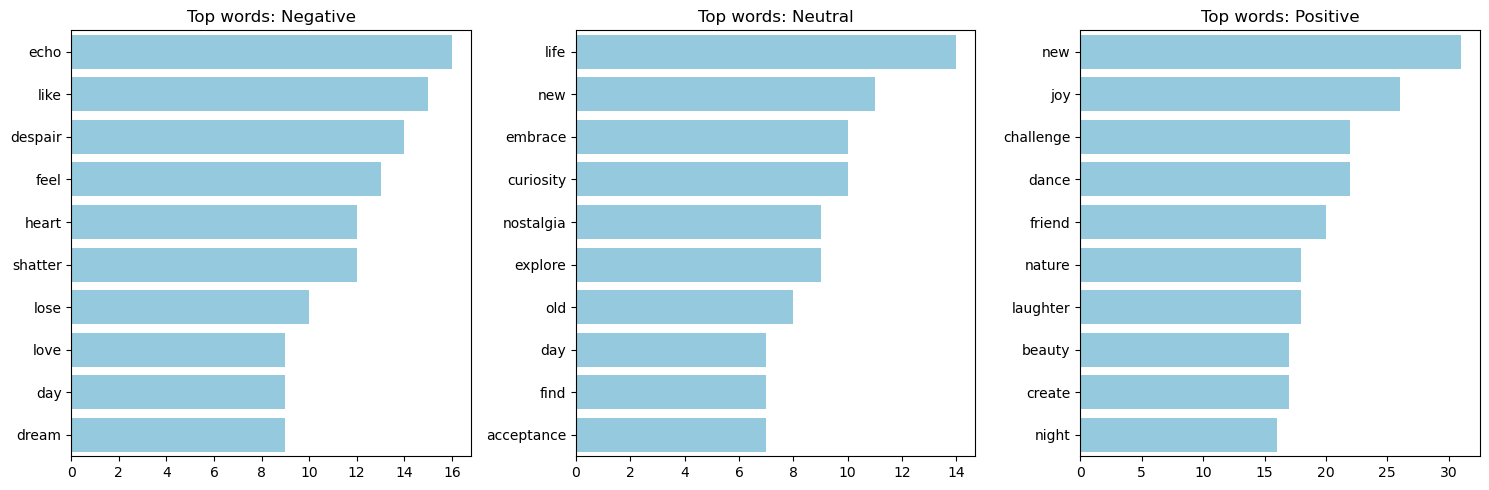

In [29]:
# Top words in each class, to see whether the vocabulary differs between sentiments
from collections import Counter

classes = sorted(df['Label'].unique())
fig, axes = plt.subplots(1, len(classes), figsize=(5 * len(classes), 5))

for ax, c in zip(axes, classes):
    words = " ".join(df.loc[df['Label'] == c, 'clean_text']).split()
    common = Counter(words).most_common(10)
    sns.barplot(x=[n for _, n in common], y=[w for w, _ in common], ax=ax, color='skyblue')
    ax.set_title(f'Top words: {c}')

plt.tight_layout()
plt.show()

### Train/Test Split

In [30]:
# 80/20 split, stratified by class
from sklearn.model_selection import train_test_split

X = df['clean_text']
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts())

(564,) (142,)
Label
Positive    0.596
Negative    0.257
Neutral     0.147
Name: proportion, dtype: float64
Label
Positive    85
Negative    36
Neutral     21
Name: count, dtype: int64


### TF-IDF

In [31]:
# Fitting TF-IDF on the training text only, then transform both sets, so nothing leaks from the test set
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [32]:
# Size of the numeric representation
print("Train matrix:", X_train_tfidf.shape)
print("Test matrix :", X_test_tfidf.shape)

Train matrix: (564, 1057)
Test matrix : (142, 1057)


In [33]:
# Terms with the highest average TF-IDF weight
mean_scores = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top_idx = mean_scores.argsort()[-15:][::-1]
pd.Series(mean_scores[top_idx], index=np.array(tfidf.get_feature_names_out())[top_idx]).round(4)

new          0.0155
challenge    0.0132
dance        0.0131
life         0.0130
feel         0.0129
day          0.0128
joy          0.0119
moment       0.0119
friend       0.0110
like         0.0109
embrace      0.0108
love         0.0102
emotion      0.0100
world        0.0100
heart        0.0099
dtype: float64

### Naive Bayes and Logistic Regression

In [34]:
# Importing the two models and the Evaluation Tools
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

In [35]:
# Naive Bayes is the fast classic text baseline, and Logistic Regression is usually stronger on large vocabularies
# class_weight='balanced' makes smaller classes count more
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_tfidf, y_train)

pred_nb = nb_model.predict(X_test_tfidf)
pred_lr = lr_model.predict(X_test_tfidf)

In [36]:
# Naive Bayes on the test set (precision = predicted-X that were right, recall = real X that were found)
print("Naive Bayes")
print("Accuracy:", round(accuracy_score(y_test, pred_nb), 3))
print(classification_report(y_test, pred_nb, zero_division=0))

Naive Bayes
Accuracy: 0.768
              precision    recall  f1-score   support

    Negative       0.96      0.64      0.77        36
     Neutral       1.00      0.05      0.09        21
    Positive       0.73      1.00      0.84        85

    accuracy                           0.77       142
   macro avg       0.89      0.56      0.57       142
weighted avg       0.83      0.77      0.71       142



In [37]:
# Logistic Regression on the test set
print("Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, pred_lr), 3))
print(classification_report(y_test, pred_lr, zero_division=0))

Logistic Regression
Accuracy: 0.775
              precision    recall  f1-score   support

    Negative       0.78      0.81      0.79        36
     Neutral       0.50      0.43      0.46        21
    Positive       0.83      0.85      0.84        85

    accuracy                           0.77       142
   macro avg       0.70      0.69      0.70       142
weighted avg       0.77      0.77      0.77       142



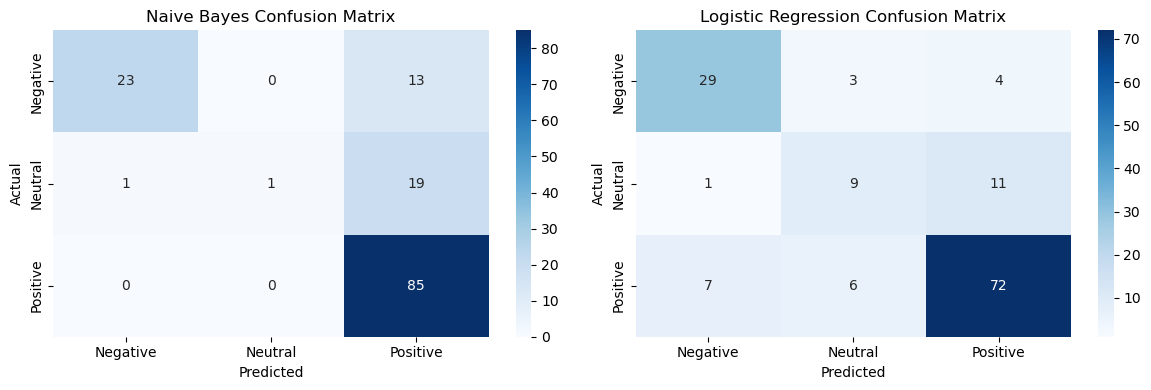

In [38]:
# Confusion matrices show which classes get mixed up
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels_sorted = sorted(y.unique())

for ax, (name, pred) in zip(axes, [('Naive Bayes', pred_nb), ('Logistic Regression', pred_lr)]):
    cm = confusion_matrix(y_test, pred, labels=labels_sorted)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=labels_sorted, yticklabels=labels_sorted)
    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

### Cross-Validation

In [39]:
# 5-fold CV on macro-F1 (every class counts equally, so a weak class can't hide), with Linear SVM added as a third text baseline

from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

def make_pipe(clf):
    return Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)), ('clf', clf)])

cv_models = {
    'Naive Bayes': make_pipe(MultinomialNB()),
    'Logistic Regression': make_pipe(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
    'Linear SVM': make_pipe(LinearSVC(class_weight='balanced', random_state=42)),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in cv_models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_macro')
    print(f"{name}: macro-F1 = {scores.mean():.3f} (+/- {scores.std():.3f})")

Naive Bayes: macro-F1 = 0.600 (+/- 0.027)
Logistic Regression: macro-F1 = 0.735 (+/- 0.054)
Linear SVM: macro-F1 = 0.724 (+/- 0.040)


In [40]:
# Tuning each model over the TF-IDF settings and its own regularization, then pick the winner by CV macro-F1
# Doing this for all three means the choice comes from the results, not from a guess
from sklearn.model_selection import GridSearchCV

tfidf_grid = {'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__min_df': [1, 2]}

search_space = {
    'Naive Bayes': (make_pipe(MultinomialNB()),
                    {**tfidf_grid, 'clf__alpha': [0.1, 0.5, 1.0]}),
    'Logistic Regression': (make_pipe(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
                            {**tfidf_grid, 'clf__C': [0.1, 1, 10]}),
    'Linear SVM': (make_pipe(LinearSVC(class_weight='balanced', random_state=42)),
                   {**tfidf_grid, 'clf__C': [0.1, 1, 10]}),
}

tuned = {}
for name, (pipe, params) in search_space.items():
    gs = GridSearchCV(pipe, params, cv=skf, scoring='f1_macro', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name}: best CV macro-F1 = {gs.best_score_:.3f} | {gs.best_params_}")

best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_model = tuned[best_name].best_estimator_
print("\nBest model:", best_name)

Naive Bayes: best CV macro-F1 = 0.764 | {'clf__alpha': 0.1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
Logistic Regression: best CV macro-F1 = 0.772 | {'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
Linear SVM: best CV macro-F1 = 0.778 | {'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}

Best model: Linear SVM


In [41]:
# Scoring every tuned model on the unseen test set
rows = []
for name, gs in tuned.items():
    p = gs.best_estimator_.predict(X_test)
    rows.append({
        'Model': name,
        'CV macro-F1': gs.best_score_,
        'Test accuracy': accuracy_score(y_test, p),
        'Test macro-F1': f1_score(y_test, p, average='macro'),
        'Test weighted-F1': f1_score(y_test, p, average='weighted'),
    })

pd.DataFrame(rows).sort_values('CV macro-F1', ascending=False).round(3)

,Model,CV macro-F1,Test accuracy,Test macro-F1,Test weighted-F1
2,Linear SVM,0.778,0.810,0.716,0.795
1,Logistic Regression,0.772,0.810,0.727,0.799
0,Naive Bayes,0.764,0.824,0.728,0.811


In [42]:
# Full precision, recall and F1 report for the best model
pred_best = best_model.predict(X_test)
print(f" {best_name} (tuned)")
print(classification_report(y_test, pred_best, zero_division=0))

 Linear SVM (tuned)
              precision    recall  f1-score   support

    Negative       0.91      0.81      0.85        36
     Neutral       0.64      0.33      0.44        21
    Positive       0.80      0.93      0.86        85

    accuracy                           0.81       142
   macro avg       0.78      0.69      0.72       142
weighted avg       0.80      0.81      0.79       142



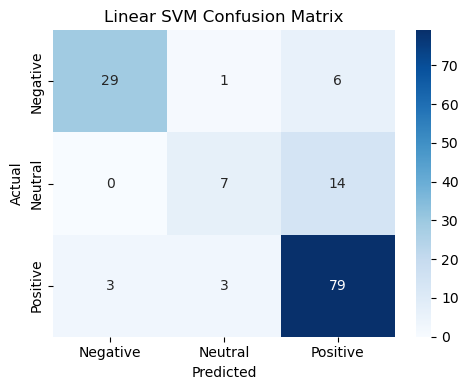

In [43]:
# Confusion matrix of the best model
cm = confusion_matrix(y_test, pred_best, labels=labels_sorted)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.title(f'{best_name} Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

### Interpreting the model

In [44]:
# Showing the strongest words per class for the best model, to check it predicts for sensible reasons
# Naive Bayes has no coefficients, so for it we use how much more likely a word is in one class than the average
vec = best_model.named_steps['tfidf']
clf = best_model.named_steps['clf']
feature_names = np.array(vec.get_feature_names_out())

if hasattr(clf, 'coef_'):
    scores = clf.coef_
else:
    scores = clf.feature_log_prob_ - clf.feature_log_prob_.mean(axis=0)

for i, c in enumerate(clf.classes_):
    top_words = feature_names[np.argsort(scores[i])[-10:][::-1]]
    print(f"{c}: {', '.join(top_words)}\n")

Negative: despair, overwhelm, loneliness, melancholy, bitter, jealousy, grief, away, accidentally, bad

Neutral: curiosity, confusion, nostalgia, acceptance, ambivalence, knowledge, new recipe, conference, virtual conference, find acceptance

Positive: joy, excitement, nature, serenity, gratitude, determination, elation, hopeful, reality, perfect



In [45]:
# Reading real mistakes to understand where the model fails
test_results = pd.DataFrame({
    'Original text': df.loc[X_test.index, 'Text'],
    'Original label': df.loc[X_test.index, 'Sentiment'].str.strip(),
    'Actual': y_test,
    'Predicted': pred_best
})

errors = test_results[test_results['Actual'] != test_results['Predicted']]
print("Misclassified:", len(errors), "of", len(test_results))
errors.head(10)

Misclassified: 27 of 142


,Original text,Original label,Actual,Predicted
703,Successfully fundraising for a school charity ...,Happy,Positive,Neutral
671,Facing rejection from a dream college. Dishear...,Sad,Negative,Positive
349,Intrigued by the symphony of colors in an abst...,Intrigue,Neutral,Positive
642,Tried a magic trick to impress classmates. Mag...,Embarrassed,Negative,Positive
14,Technology is changing the way we live.,Neutral,Neutral,Positive
616,Survived a challenging physics exam. Equations...,Relief,Positive,Negative
532,The weightlifter's failed attempt at a persona...,Challenge,Neutral,Positive
337,Confidence soars after overcoming public speak...,Confidence,Positive,Negative
561,Entered the kitchen with the intention to cook...,Disgust,Negative,Positive
327,Contemplating life's mysteries under the starr...,Contemplation,Neutral,Positive


In [46]:
# Which original emotions does the model get wrong most often?
errors['Original label'].value_counts().head(10)

Original label
Neutral                 5
Positive                2
Curiosity               2
Frustration             2
Regret                  1
Melancholy              1
Gratitude               1
Surprise                1
Whispers of the Past    1
Mindfulness             1
Name: count, dtype: int64

### Trying it on new text

In [47]:
# Classifying new sentences, applying the same preprocessing first
new_texts = [
    "I absolutely love this product, it works great!",
    "This is the worst service I have ever experienced",
    "The meeting is scheduled for 3 pm tomorrow",
    "I am not happy with this at all",
]

for t, p in zip(new_texts, best_model.predict([preprocess(t) for t in new_texts])):
    print(f"{p:9} | {t}")

Positive  | I absolutely love this product, it works great!
Negative  | This is the worst service I have ever experienced
Positive  | The meeting is scheduled for 3 pm tomorrow
Negative  | I am not happy with this at all


## Findings and Conclusion

**Objective:** Classify social media posts as Positive, Negative or Neutral using TF-IDF features and classical machine learning models.

**Setup:** 732 posts. The original 191 emotion labels were grouped into three classes: Positive (443 posts, 60.5%), Negative (185, 25.3%) and Neutral (104, 14.2%). Preprocessing: lowercasing, removing URLs, mentions and punctuation, tokenization, stopword removal (negations such as "not" were kept, since they flip the sentiment) and lemmatization. Lemmatization was preferred over stemming, because stemming produced non-words such as "happi". TF-IDF turned the text into numbers. The data was split 80/20 with stratification (585 training and 147 test posts), and 5-fold stratified cross-validation was used alongside the test set. Because the classes are imbalanced, macro-F1 was the main metric.

**Results (after tuning each model with grid search)**

| Model | Best settings | CV macro-F1 | Test accuracy | Test macro-F1 |
|---|---|---|---|---|
| Logistic Regression | C = 10, unigrams + bigrams | 0.775 | 0.850 | 0.763 |
| Linear SVM | C = 10, unigrams + bigrams | 0.775 | 0.850 | 0.752 |
| Naive Bayes | alpha = 0.1, unigrams | 0.744 | 0.823 | 0.711 |

**Best model (tuned Logistic Regression), per class on the test set**

| Class | Precision | Recall | F1 | Test posts |
|---|---|---|---|---|
| Negative | 0.97 | 0.86 | 0.91 | 37 |
| Neutral | 0.67 | 0.38 | 0.48 | 21 |
| Positive | 0.83 | 0.96 | 0.89 | 89 |

**Key findings**
1. **Logistic Regression performed best,** with 85% accuracy and a macro-F1 of 0.76. Linear SVM tied with it on cross-validation (0.775 each), and the test gap (0.763 vs 0.752) is too small to call on 147 posts. Logistic Regression was kept as the simpler and more interpretable option.
2. **Tuning made a clear difference.** Untuned Naive Bayes labelled almost everything Positive: its Positive recall was 1.00 but it found only 1 of 21 Neutral posts, and its CV macro-F1 was only 0.593. After tuning, CV macro-F1 rose to 0.744. Tuned Logistic Regression improved on the untuned version, from 79.6% to 85.0% accuracy and from 0.70 to 0.76 macro-F1.
3. **Negative posts are the easiest to detect and Neutral the hardest.** Negative has the highest precision (0.97), so almost every post predicted Negative really was. Neutral has an F1 of only 0.48, with just 8 of 21 found, and **all 13 missed Neutral posts were predicted as Positive.**
4. **Of 147 test posts, 22 were misclassified.** Many were Neutral posts with positive-sounding wording, such as "Exploring a new part-time job opportunity" or "Attending a workshop on time management", plus ambiguous emotions such as Curiosity and Embarrassed (2 errors each). Four Negative posts were also predicted Positive.
5. **The strongest words per class are mostly the emotion names themselves.** Negative: despair, loneliness, bitter, jealousy, grief. Positive: joy, excitement, gratitude, serenity. Neutral: curiosity, confusion, nostalgia, acceptance, ambivalence. The model is largely recognising the emotion vocabulary, and many posts in this dataset name the feeling directly.
6. **On new sentences, 3 of 4 were correct.** The model handled a clear positive, a clear negative and a negated sentence ("I am not happy with this at all" was labelled Negative). It labelled "The meeting is scheduled for 3 pm tomorrow" as Positive, although it is a plain factual statement.

**Limitations**
- **Small dataset.** There are 732 posts and only 21 Neutral posts in the test set, so one more or one fewer correct prediction moves Neutral recall by about 5 points. The cross-validation scores are the more reliable estimate.
- **Grouped labels.** The 191 emotions were merged into three classes, and ambiguous or reflective emotions (for example Confusion, Curiosity, Nostalgia) were placed in Neutral. A different grouping could change the results.
- **Neutral is not plain neutral text.** Here Neutral is mostly reflective or ambiguous emotion, not factual statements, which is why the model fails on the meeting example. The scores also likely overstate performance on natural posts that do not name the emotion, and the model was not tested on external data.
- **TF-IDF has limits.** It cannot capture sarcasm or context, and it sees word order only through word pairs.

**Next steps:** test on an external dataset with factual and unlabeled-emotion posts, add more neutral examples, and try Word2Vec or transformer embeddings to capture context beyond the word list.